# Hindu Kush Himalaya (HKH) Glacier Mass Change and ERA5-Land Climate: Exploratory Data Analysis

This notebook explores a gridded glacier mass-change dataset and associated ERA5-Land climate predictors over the Hindu Kush Himalaya (HKH), for hydrological years **1991–2024**.

The analysis is descriptive: it checks data quality, summarizes target and climate distributions, examines temporal and spatial patterns, and measures pairwise associations. It does **not** train or validate a predictive model, establish causation, or independently validate the upstream glacier mass-change product.


## 0. Study design, data interpretation, and limitations

- **Hydrological-year convention:** the supplied data labels each hydrological year by its ending year. For example, HY1991 is intended to represent **1 April 1990 through 31 March 1991** (equivalently, the half-open interval from 1 April 1990 to 1 April 1991). The annual table contains `time` values set to 1 January of the label year; that timestamp is a label, not the start date of the hydrological period.
- **Spatial unit:** each row represents a target grid-cell coordinate and hydrological year, not necessarily an individually identified glacier. Coordinates alone do not establish a glacier identity or permit glacier-specific conclusions.
- **Study footprint:** the supplied coordinates cover a broad part of the HKH, not Nepal alone. Results must therefore be described as HKH-wide unless a separate Nepal-only subset is explicitly created and documented.
- **Target interpretation:** `glacier_mass_change_gt` and `glacier_mass_change_mwe` are treated as values supplied by the gridded target product. Do not describe them as direct field observations unless the source documentation supports that wording.
- **Climate aggregation and units:** climate columns are already aggregated in the input table. This notebook does not reconstruct the monthly-to-hydrological-year calculation. The physical units, sign conventions, and aggregation rules—especially for accumulated radiation, precipitation, snowfall, runoff, melt, and evaporation fields—must be confirmed against the original ERA5-Land metadata and the processing script before interpreting magnitudes.
- **Interpretation:** correlation and trend lines are descriptive. Spatial dependence, repeated measurements of the same grid cells, temporal autocorrelation, shared climate gradients, and possible dependencies in the target-product construction mean that simple p-values and pooled correlations should not be interpreted as independent-sample evidence or causality.
- **Machine learning readiness:** a balanced panel is useful, but it does not by itself guarantee predictive validity. Any future model should use a clearly defined forecast origin, avoid target leakage, and evaluate on time-blocked and/or spatially blocked holdouts.


## 1. Load the dataset and establish the analysis schema

The following cells load the prepared grid-cell-by-year table, inspect the supplied fields, and remove auxiliary processing columns from the analysis frame. The original input file should be retained unchanged so that period-coverage flags and other audit fields remain available for traceability.


### Variable dictionary: provisional interpretation, not independent unit verification

The descriptions below summarize the intended meaning of the column names. They are **not a substitute for checking the source product metadata**. In particular, units shown for ERA5-Land variables can depend on whether the original field was an instantaneous/state variable, a monthly mean, or an accumulated quantity and on how the upstream script aggregated it.

| Variable | Intended meaning | Unit / interpretation to verify |
| :--- | :--- | :--- |
| `glacier_mass_change_gt` | Gridded total mass-change estimate | Gt per reporting period, according to target-product documentation |
| `glacier_mass_change_mwe` | Gridded specific mass-change estimate | m water equivalent (m w.e.) per reporting period, according to target-product documentation |
| `glacier_area_km2` | Glacier or glacierized area associated with the target cell | km²; verify whether this is a static or year-specific area and how it is assigned to cells |
| `uncertainty_gt` | Uncertainty associated with total mass change | Gt; verify confidence level and whether it is standard deviation or another uncertainty measure |
| `uncertainty_mwe` | Uncertainty associated with specific mass change | m w.e.; verify definition and confidence level |
| `t2m` | 2-metre air temperature | K in native ERA5-Land data; verify if converted |
| `snowc` | Snow cover | Often represented as a percentage; verify the source units and aggregation |
| `sde` | Snow depth | m in native ERA5-Land data; verify aggregation |
| `sd` | Snow depth water equivalent | m w.e. in the intended interpretation; verify source variable and aggregation |
| `sf` | Snowfall | Native units and temporal aggregation require verification |
| `smlt` | Snowmelt | Native units and temporal aggregation require verification |
| `ssr` | Surface net solar radiation | Energy flux/accumulation units depend on source representation and aggregation |
| `str` | Surface net thermal radiation | Energy flux/accumulation units depend on source representation and aggregation |
| `ro` | Total runoff | Native units and temporal aggregation require verification |
| `es` | Evaporation from snow | Check sign convention and native units |
| `sro` | Surface runoff | Native units and temporal aggregation require verification |
| `e` | Total evaporation | Check sign convention and native units |
| `u10`, `v10` | 10-metre wind components | m/s in native ERA5-Land data; verify if converted |
| `tp` | Total precipitation | Native units and temporal aggregation require verification |

**Important:** plausible-looking numeric ranges do not prove that units or aggregation are correct. Confirm these fields against the original NetCDF/GRIB metadata and the code used to construct this annual table before making physical interpretations.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import warnings

# Ignore all warnings
warnings.filterwarnings('ignore')

# --- Google Colab option ---
ON_COLAB = False
try:
    import google.colab  # noqa: F401
    ON_COLAB = True
except ImportError:
    pass

if ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_PATH = Path("/content/drive/MyDrive/hkh_glacier_mass_change_era5land_hydrological_year_eda.csv")
else:
    # Change this to your local CSV path if running outside Colab.
    DATA_PATH = Path(r"E:\glacier_research\processed_data\hkh_glacier_mass_change_era5land_hydrological_year_eda.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Set DATA_PATH to the location of hkh_glacier_mass_change_era5land_hydrological_year_eda.csv."
    )

print("Input:", DATA_PATH)
print("File size (MB):", round(DATA_PATH.stat().st_size / 1e6, 2))

Input: E:\glacier_research\processed_data\hkh_glacier_mass_change_era5land_hydrological_year_eda.csv
File size (MB): 11.11


In [7]:
df = pd.read_csv(DATA_PATH)

# Display the first 5 rows
df.head()

,time,target_latitude,target_longitude,glacier_mass_change_gt,glacier_mass_change_mwe,glacier_area_km2,uncertainty_gt,uncertainty_mwe,spatial_ref,target_year_label,...,sro,e__months_valid,e,u10__months_valid,u10,v10__months_valid,v10,tp__months_valid,tp,climate_match_status
0,1991-01-01,39.25,67.75,-0.012155,-0.611,19.886,0.001858,0.088,NaN,1991,...,0.533359,12,-0.356275,12,-0.145833,12,0.575647,12,0.967207,matched
1,1991-01-01,39.25,68.25,-0.010231,-0.357,28.650,0.003317,0.114,NaN,1991,...,0.682236,12,-0.319138,12,-0.093626,12,0.452279,12,1.079204,matched
2,1991-01-01,39.25,68.75,-0.004373,-0.323,13.532,0.002644,0.195,NaN,1991,...,0.730049,12,-0.296594,12,-0.114099,12,0.337503,12,1.341070,matched
3,1991-01-01,39.25,69.25,-0.012064,-0.262,46.123,0.002603,0.055,NaN,1991,...,0.442233,12,-0.308213,12,-0.159165,12,0.191086,12,1.209151,matched
4,1991-01-01,39.25,69.75,-0.046760,-0.287,162.760,0.004449,0.023,NaN,1991,...,0.808816,12,-0.320587,12,0.030128,12,0.001242,12,1.637033,matched


In [4]:
df.nunique()

target_latitude           25
target_longitude          74
hydrological_year         34
n_unique_months            1
complete_12_months         1
t2m__months_valid          1
t2m                    23698
snowc__months_valid        1
snowc                  23698
sde__months_valid          1
sde                    23698
sd__months_valid           1
sd                     23698
sf__months_valid           1
sf                     23698
smlt__months_valid         1
smlt                   23698
ssr__months_valid          1
ssr                    23698
str__months_valid          1
str                    23698
ro__months_valid           1
ro                     23698
es__months_valid           1
es                     23698
sro__months_valid          1
sro                    23698
e__months_valid            1
e                      23698
u10__months_valid          1
u10                    23698
v10__months_valid          1
v10                    23698
tp__months_valid           1
tp            

In [8]:
df = df.drop(columns=['spatial_ref','target_year_label','period_start','period_end_exclusive','n_unique_months','complete_12_months','t2m__months_valid','snowc__months_valid','sde__months_valid','sd__months_valid','sf__months_valid','smlt__months_valid','ssr__months_valid','str__months_valid','ro__months_valid','es__months_valid','sro__months_valid','e__months_valid','u10__months_valid','v10__months_valid','tp__months_valid','climate_match_status'])
df

,time,target_latitude,target_longitude,glacier_mass_change_gt,glacier_mass_change_mwe,glacier_area_km2,uncertainty_gt,uncertainty_mwe,hydrological_year,t2m,...,smlt,ssr,str,ro,es,sro,e,u10,v10,tp
0,1991-01-01,39.25,67.75,-0.012155,-0.611,19.886,0.001858,0.088,1991,275.058522,...,0.741012,120.541125,-66.744644,0.735957,-0.005813,0.533359,-0.356275,-0.145833,0.575647,0.967207
1,1991-01-01,39.25,68.25,-0.010231,-0.357,28.650,0.003317,0.114,1991,272.706248,...,0.774721,106.711320,-61.095066,0.863623,-0.005086,0.682236,-0.319138,-0.093626,0.452279,1.079204
2,1991-01-01,39.25,68.75,-0.004373,-0.323,13.532,0.002644,0.195,1991,272.958195,...,0.957659,105.937037,-58.112765,1.148000,-0.004855,0.730049,-0.296594,-0.114099,0.337503,1.341070
3,1991-01-01,39.25,69.25,-0.012064,-0.262,46.123,0.002603,0.055,1991,271.960346,...,0.889912,108.835358,-54.938504,0.979578,-0.014323,0.442233,-0.308213,-0.159165,0.191086,1.209151
4,1991-01-01,39.25,69.75,-0.046760,-0.287,162.760,0.004449,0.023,1991,271.006137,...,1.089590,100.933710,-47.384238,1.376528,-0.016002,0.808816,-0.320587,0.030128,0.001242,1.637033
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23693,2024-01-01,27.75,92.75,-0.090054,-1.248,72.172,0.008065,0.093,2024,276.825972,...,1.045726,99.563325,-39.007247,7.180833,-0.001763,4.810409,-0.459220,0.417633,-0.620211,7.878217
23694,2024-01-01,27.75,98.25,-0.000837,-1.528,0.548,0.000329,0.595,2024,278.803078,...,0.279910,134.274273,-46.598853,2.894589,-0.002735,1.524012,-0.743924,-0.426927,-0.459663,3.731932
23695,2024-01-01,27.75,98.75,-0.000287,-1.345,0.213,0.000129,0.602,2024,276.223056,...,0.433449,130.064805,-49.409296,1.620086,-0.008931,0.729712,-0.639035,0.003947,-0.276012,2.393850
23696,2024-01-01,27.25,88.75,-0.000448,-1.882,0.238,0.000119,0.490,2024,283.116092,...,0.124419,138.029204,-40.047612,3.111926,-0.003295,1.422772,-0.779880,-0.244838,-0.613643,3.872219


## 2. Data quality, schema, and integrity checks

This section checks data types, missingness, summary statistics, the year/grid-cell key, and the spatial grid. These checks describe the table as supplied; they do not independently validate the scientific accuracy of the target estimates or the upstream temporal aggregation.


### 2.1 Schema and basic statistics

Inspect data types, non-null counts, missing values, and numeric ranges. Large or unusual values should be investigated against source metadata and processing logs rather than automatically removed or clipped.


In [9]:
# Display data types and non-null counts
print("--- Dataset Info ---")
df.info()

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 23698 entries, 0 to 23697
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   time                     23698 non-null  str    
 1   target_latitude          23698 non-null  float64
 2   target_longitude         23698 non-null  float64
 3   glacier_mass_change_gt   23698 non-null  float64
 4   glacier_mass_change_mwe  23698 non-null  float64
 5   glacier_area_km2         23698 non-null  float64
 6   uncertainty_gt           23698 non-null  float64
 7   uncertainty_mwe          23698 non-null  float64
 8   hydrological_year        23698 non-null  int64  
 9   t2m                      23698 non-null  float64
 10  snowc                    23698 non-null  float64
 11  sde                      23698 non-null  float64
 12  sd                       23698 non-null  float64
 13  sf                       23698 non-null  float64
 14  smlt        

In [ ]:
df['time'] = pd.to_datetime(df['time'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23698 entries, 0 to 23697
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   time                     23698 non-null  datetime64[ns]
 1   target_latitude          23698 non-null  float64       
 2   target_longitude         23698 non-null  float64       
 3   glacier_mass_change_gt   23698 non-null  float64       
 4   glacier_mass_change_mwe  23698 non-null  float64       
 5   glacier_area_km2         23698 non-null  float64       
 6   uncertainty_gt           23698 non-null  float64       
 7   uncertainty_mwe          23698 non-null  float64       
 8   hydrological_year        23698 non-null  int64         
 9   t2m                      23698 non-null  float64       
 10  snowc                    23698 non-null  float64       
 11  sde                      23698 non-null  float64       
 12  sd                       23698 n

In [10]:
print('\n--- COLUMN AUDIT ---')
column_audit = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'non_null': df.notna().sum(),
    'missing': df.isna().sum(),
    'missing_pct': df.isna().mean().mul(100),
    'n_unique': df.nunique(dropna=True)
}).sort_values('missing_pct', ascending=False)
display(column_audit)


--- COLUMN AUDIT ---


,dtype,non_null,missing,missing_pct,n_unique
time,str,23698,0,0.0,34
target_latitude,float64,23698,0,0.0,25
target_longitude,float64,23698,0,0.0,74
glacier_mass_change_gt,float64,23698,0,0.0,23698
glacier_mass_change_mwe,float64,23698,0,0.0,2486
glacier_area_km2,float64,23698,0,0.0,19714
uncertainty_gt,float64,23698,0,0.0,23698
uncertainty_mwe,float64,23698,0,0.0,1116
hydrological_year,int64,23698,0,0.0,34
t2m,float64,23698,0,0.0,23698


In [11]:
# Summary statistics
print("\n--- Summary Statistics ---")
display(df.describe())


--- Summary Statistics ---


,target_latitude,target_longitude,glacier_mass_change_gt,glacier_mass_change_mwe,glacier_area_km2,uncertainty_gt,uncertainty_mwe,hydrological_year,t2m,snowc,...,smlt,ssr,str,ro,es,sro,e,u10,v10,tp
count,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,...,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000
mean,33.591463,85.373386,-0.027012,-0.296623,114.081838,0.011472,0.263491,2007.500000,268.394643,41.704567,...,0.327871,138.216609,-79.847600,0.503963,-0.034549,0.267942,-0.358935,0.522925,0.373439,0.874279
std,3.374958,9.062140,0.114344,0.478046,208.361936,0.028196,0.261760,9.810915,5.207344,22.299327,...,0.255846,31.739194,20.171599,0.702523,0.022512,0.416571,0.130060,0.662751,0.517732,0.745258
min,27.250000,67.250000,-2.476935,-2.143000,0.016000,0.000008,0.014000,1991.000000,253.178826,0.398443,...,0.011651,42.873176,-134.366130,0.001538,-0.122529,0.001455,-0.918926,-1.402539,-1.630871,0.064305
25%,30.750000,77.750000,-0.026263,-0.609000,4.410000,0.001465,0.073000,1999.000000,264.975129,23.695347,...,0.165781,116.700911,-94.046766,0.094235,-0.046702,0.035638,-0.423875,0.009967,0.031901,0.443735
50%,33.750000,85.750000,-0.002581,-0.277500,28.983500,0.004191,0.186000,2007.500000,267.637384,41.069785,...,0.240792,139.527261,-79.808071,0.264903,-0.029669,0.120804,-0.360219,0.373672,0.326592,0.634774
75%,36.250000,92.750000,0.000100,0.039000,132.023250,0.010922,0.343000,2016.000000,271.326091,59.239695,...,0.410255,158.245827,-64.759806,0.646595,-0.017332,0.337201,-0.283972,0.953856,0.676823,1.041403
max,39.250000,103.750000,1.252720,1.181000,2029.167000,0.426087,1.547000,2024.000000,288.627898,99.581715,...,2.516222,216.830497,-24.407498,9.002801,0.028726,6.338046,-0.010038,2.580551,2.200659,9.641115


In [12]:
# Core schema
YEAR_COL = 'hydrological_year'
TIME_COL = 'time'
LAT_COL = 'target_latitude'
LON_COL = 'target_longitude'
AREA_COL = 'glacier_area_km2'

TARGETS = ['glacier_mass_change_gt', 'glacier_mass_change_mwe']
UNCERTAINTY_COLS = ['uncertainty_gt', 'uncertainty_mwe']

CLIMATE_CANDIDATES = [
    't2m', 'snowc', 'sde', 'sd', 'sf', 'smlt', 'ssr', 'str',
    'ro', 'es', 'sro', 'e', 'u10', 'v10', 'tp'
]
CLIMATE = [c for c in CLIMATE_CANDIDATES if c in df.columns]
TARGETS = [c for c in TARGETS if c in df.columns]
UNCERTAINTY_COLS = [c for c in UNCERTAINTY_COLS if c in df.columns]

df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors='coerce')
df[YEAR_COL] = pd.to_numeric(df[YEAR_COL], errors='coerce').astype('Int64')

print('Hydrological-year range:', df[YEAR_COL].min(), 'to', df[YEAR_COL].max())
print('Number of years:', df[YEAR_COL].nunique())
print('Unique coordinate pairs:', df[[LAT_COL, LON_COL]].drop_duplicates().shape[0])
print('Unique grid cells:', df[[LAT_COL, LON_COL]].drop_duplicates().shape[0])

KEY = [YEAR_COL, LAT_COL, LON_COL]
duplicate_key_mask = df.duplicated(KEY, keep=False)
print('Rows involved in duplicate year-grid keys:', int(duplicate_key_mask.sum()))
if duplicate_key_mask.any():
    display(df.loc[duplicate_key_mask].sort_values(KEY).head(50))

print('Exact duplicate rows:', int(df.duplicated().sum()))


Hydrological-year range: 1991 to 2024
Number of years: 34
Unique coordinate pairs: 697
Unique grid cells: 697
Rows involved in duplicate year-grid keys: 0
Exact duplicate rows: 0


## 3. Spatial and temporal coverage

The following checks quantify how many target grid cells are represented in each year, how many years are represented at each grid cell, and the geographic footprint of the grid. A balanced grid-cell/year table is a data-structure property; it does not mean each grid cell represents a single glacier or that all estimates have equal uncertainty.


In [13]:
# Is the panel balanced? Count observations per year and per grid cell.
records_per_year = df.groupby(YEAR_COL).size().rename('n_records')
records_per_cell = df.groupby([LAT_COL, LON_COL]).size().rename('n_year_records')

display(records_per_year.to_frame().T)

hydrological_year,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
n_records,697,697,697,697,697,697,697,697,697,697,...,697,697,697,697,697,697,697,697,697,697


In [14]:
display(records_per_year.describe().to_frame('records_per_year'))

,records_per_year
count,34.0
mean,697.0
std,0.0
min,697.0
25%,697.0
50%,697.0
75%,697.0
max,697.0


In [15]:
display(records_per_cell.describe().to_frame('years_per_grid_cell'))

,years_per_grid_cell
count,697.0
mean,34.0
std,0.0
min,34.0
25%,34.0
50%,34.0
75%,34.0
max,34.0


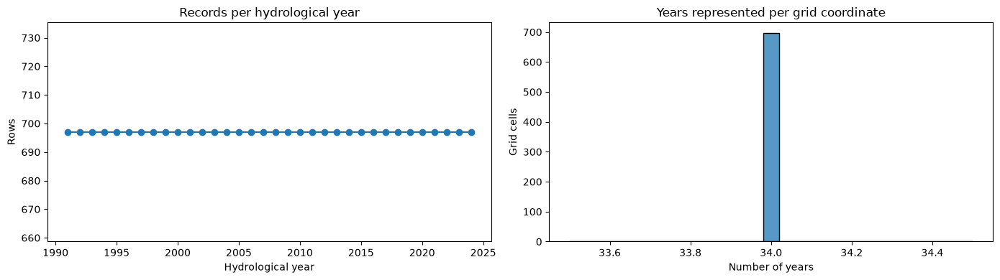

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

year_counts = df.groupby("hydrological_year", dropna=False).size().rename("rows")
cell_year_counts = df.groupby(["target_latitude", "target_longitude"])["hydrological_year"].nunique().rename("n_years")

year_counts.sort_index().plot(ax=axes[0], marker="o")
axes[0].set(title="Records per hydrological year", xlabel="Hydrological year", ylabel="Rows")
sns.histplot(cell_year_counts, bins=25, ax=axes[1])
axes[1].set(title="Years represented per grid coordinate", xlabel="Number of years", ylabel="Grid cells")
plt.tight_layout()
plt.show()

In [17]:
coords = df[[LAT_COL, LON_COL]].dropna().drop_duplicates()
print('Latitude range:', coords[LAT_COL].min(), 'to', coords[LAT_COL].max())
print('Longitude range:', coords[LON_COL].min(), 'to', coords[LON_COL].max())

for c in [LAT_COL, LON_COL]:
    vals = np.sort(coords[c].unique())
    diffs = np.diff(vals)
    print(f'\n{c}: unique={len(vals)}, common increments:')
    display(pd.Series(np.round(diffs, 6)).value_counts().head(10).to_frame('frequency'))


Latitude range: 27.25 to 39.25
Longitude range: 67.25 to 103.75

target_latitude: unique=25, common increments:


,frequency
0.5,24



target_longitude: unique=74, common increments:


,frequency
0.5,73


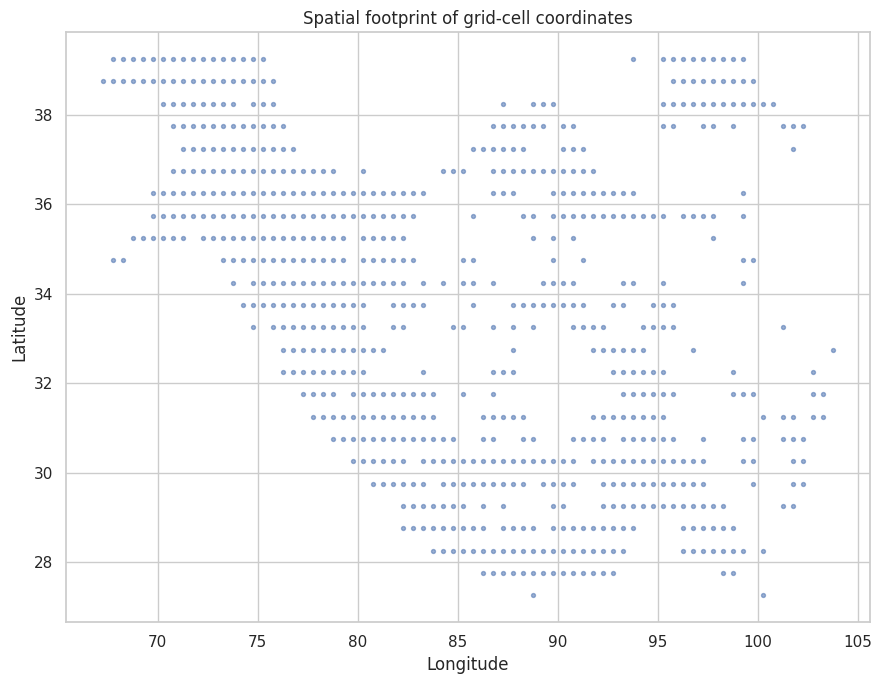

In [ ]:
plt.figure(figsize=(9, 7))
plt.scatter(coords[LON_COL], coords[LAT_COL], s=8, alpha=.55)
plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.title('Spatial footprint of grid-cell coordinates')
plt.tight_layout(); plt.show()

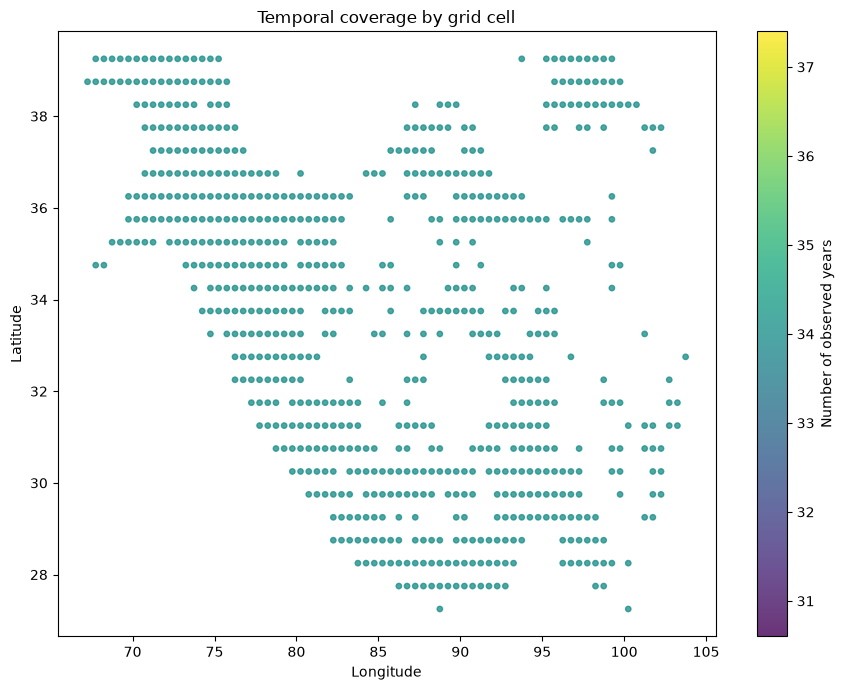

In [18]:
# Number of observed years at each grid coordinate.
cell_coverage = df.groupby([LAT_COL, LON_COL])[YEAR_COL].nunique().rename('n_years').reset_index()
plt.figure(figsize=(9, 7))
sc = plt.scatter(cell_coverage[LON_COL], cell_coverage[LAT_COL],
                 c=cell_coverage['n_years'], s=15, alpha=.8)
plt.colorbar(sc, label='Number of observed years')
plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.title('Temporal coverage by grid cell')
plt.tight_layout(); plt.show()


In [19]:
display(cell_coverage['n_years'].describe())

count    697.0
mean      34.0
std        0.0
min       34.0
25%       34.0
50%       34.0
75%       34.0
max       34.0
Name: n_years, dtype: float64

## 4. Target and climate feature distributions

Examine the distribution and spread of the two target metrics, their associated uncertainty fields, glacier-area values, and climate predictors. Histograms and boxplots are descriptive diagnostics; extreme values are retained unless an independently justified data-quality issue is found.


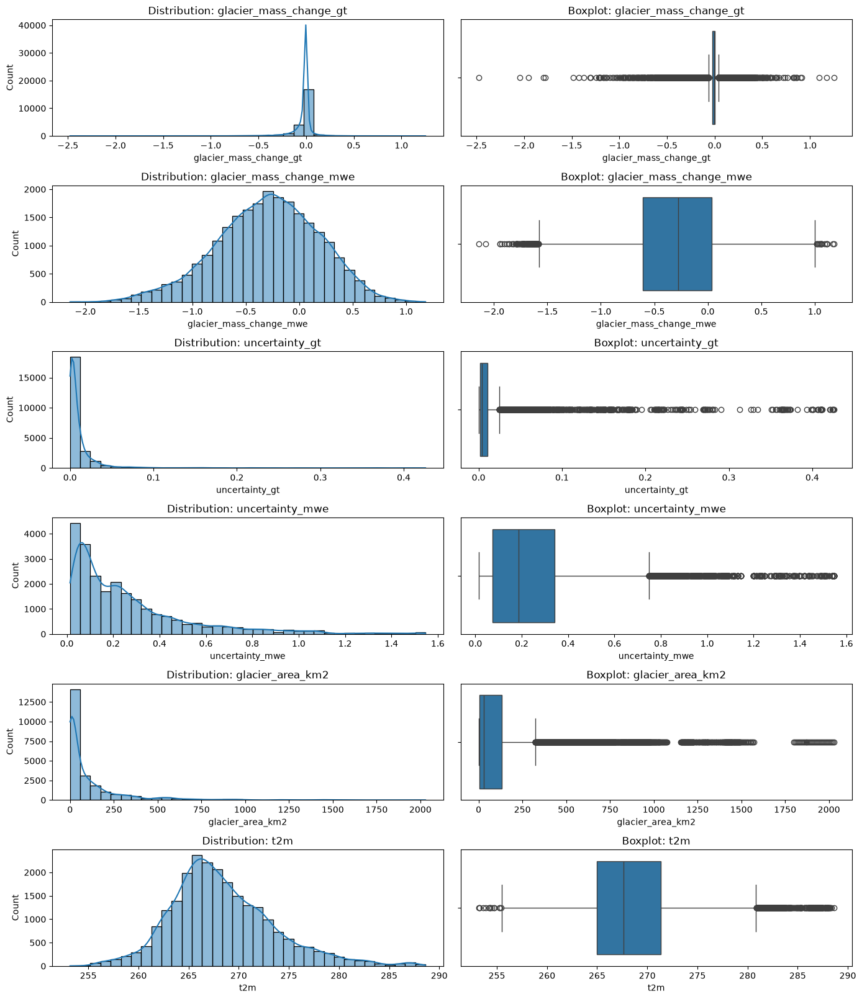

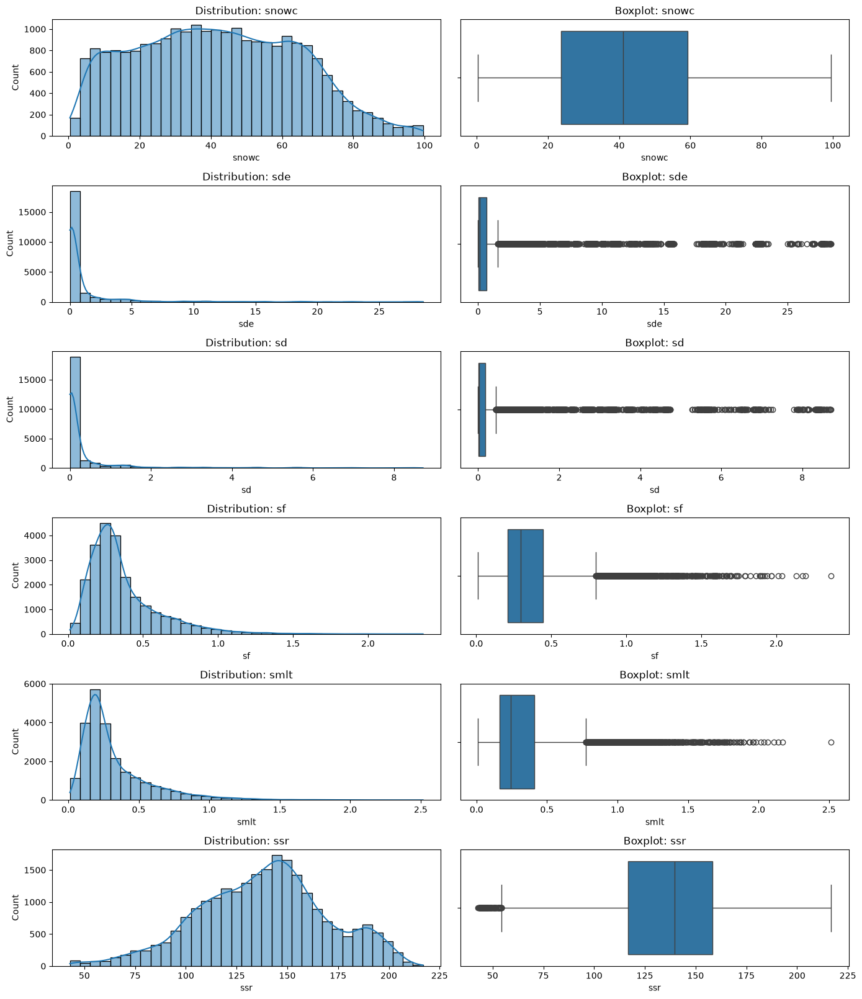

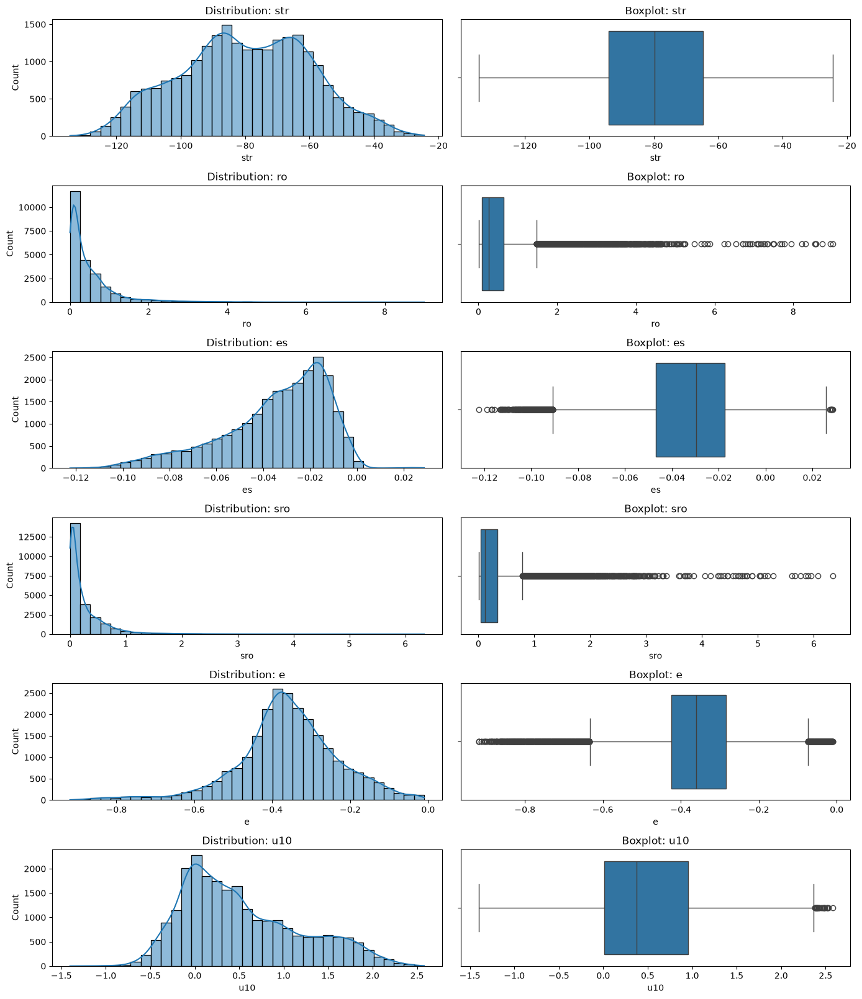

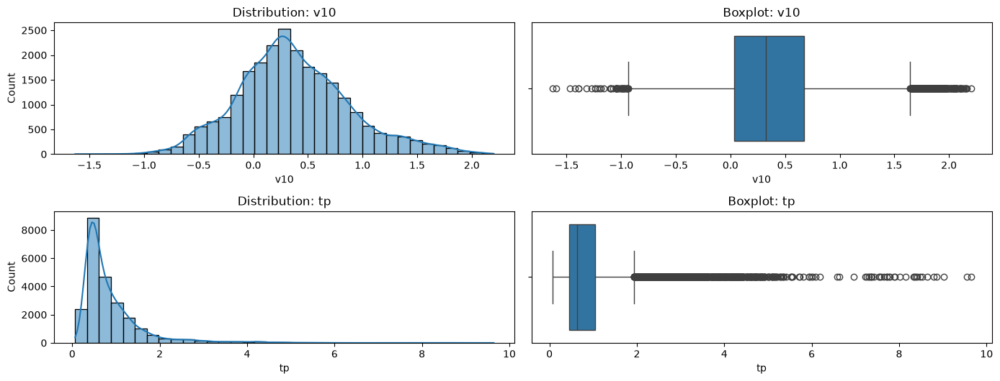

In [20]:
analysis_cols = [c for c in TARGETS + UNCERTAINTY_COLS + [AREA_COL] + CLIMATE
                 if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]

for start in range(0, len(analysis_cols), 6):
    batch = analysis_cols[start:start+6]
    fig, axes = plt.subplots(len(batch), 2, figsize=(14, max(3, 2.7*len(batch))))
    if len(batch) == 1: axes = np.array([axes])
    for i, col in enumerate(batch):
        sns.histplot(df[col].dropna(), kde=True, bins=35, ax=axes[i,0])
        axes[i,0].set_title(f'Distribution: {col}')
        sns.boxplot(x=df[col], ax=axes[i,1])
        axes[i,1].set_title(f'Boxplot: {col}')
    plt.tight_layout(); plt.show()


In [21]:
for target in TARGETS:
    s = df[target].dropna()
    print(f'\n{target}:')
    print('n:',len(s),'mean:',s.mean(),'median:',s.median(),
          'std:',s.std(),'min:',s.min(),'max:',s.max())
    print('negative %:',(s<0).mean()*100,
          '| positive %:',(s>0).mean()*100,
          '| zero %:',(s==0).mean()*100)


glacier_mass_change_gt:
n: 23698 mean: -0.027011682303988975 median: -0.00258117192488185 std: 0.1143444035595518 min: -2.476934759427536 max: 1.2527196135158942
negative %: 72.29724027344079 | positive %: 27.7027597265592 | zero %: 0.0

glacier_mass_change_mwe:
n: 23698 mean: -0.2966230905561651 median: -0.2775 std: 0.4780462846876006 min: -2.143 max: 1.181
negative %: 72.26770191577349 | positive %: 27.65634230736771 | zero %: 0.07595577685880664



glacier_mass_change_gt vs uncertainty_gt


,glacier_mass_change_gt,uncertainty_gt,uncertainty_to_abs_estimate
count,23698.000000,23698.000000,23698.000000
mean,-0.027012,0.011472,8.337082
std,0.114344,0.028196,535.274656
min,-2.476935,0.000008,0.051217
25%,-0.026263,0.001465,0.203163
50%,-0.002581,0.004191,0.507718
75%,0.000100,0.010922,1.383011
max,1.252720,0.426087,77996.175144


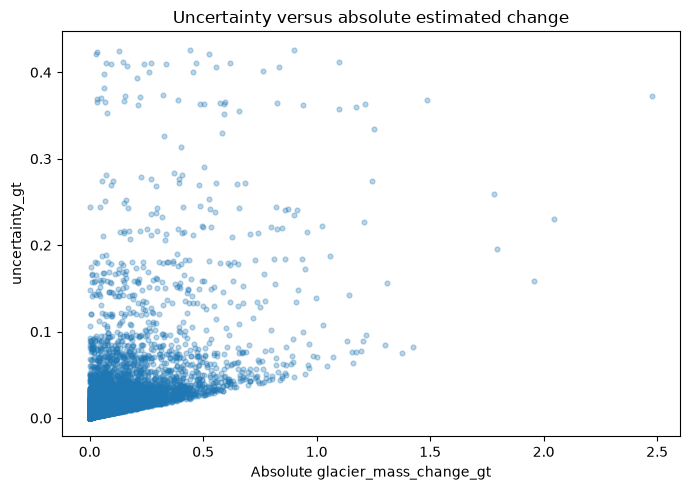


glacier_mass_change_mwe vs uncertainty_mwe


,glacier_mass_change_mwe,uncertainty_mwe,uncertainty_to_abs_estimate
count,23698.000000,23698.000000,23680.000000
mean,-0.296623,0.263491,2.463812
std,0.478046,0.261760,16.056020
min,-2.143000,0.014000,0.011394
25%,-0.609000,0.073000,0.197018
50%,-0.277500,0.186000,0.504808
75%,0.039000,0.343000,1.379884
max,1.181000,1.547000,910.000000


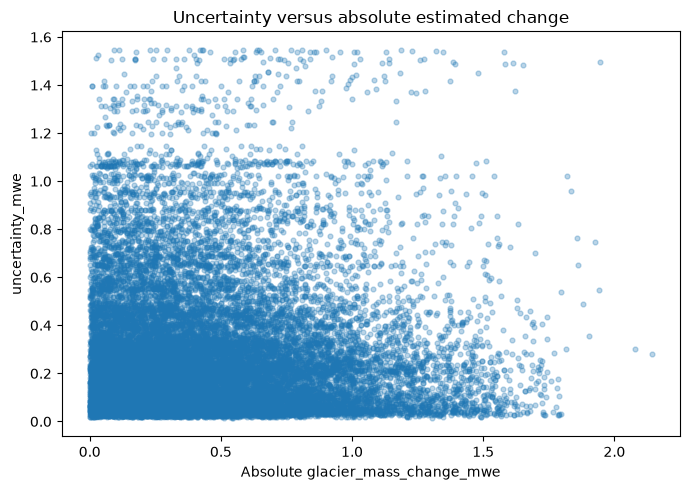

In [22]:
# Compare uncertainty with the magnitude of the estimate.
for target, unc in [('glacier_mass_change_gt','uncertainty_gt'),
                    ('glacier_mass_change_mwe','uncertainty_mwe')]:
    if {target,unc}.issubset(df.columns):
        temp=df[[target,unc]].dropna().copy()
        temp['abs_estimate']=temp[target].abs()
        temp['uncertainty_to_abs_estimate']=temp[unc]/temp['abs_estimate'].replace(0,np.nan)
        print(f'\n{target} vs {unc}')
        display(temp[[target,unc,'uncertainty_to_abs_estimate']].describe())
        plt.figure(figsize=(7,5))
        plt.scatter(temp['abs_estimate'],temp[unc],alpha=.3,s=12)
        plt.xlabel(f'Absolute {target}'); plt.ylabel(unc)
        plt.title('Uncertainty versus absolute estimated change')
        plt.tight_layout(); plt.show()


### 4.1 Pairwise correlation analysis

The heatmap and target-correlation plot show **pooled, unadjusted Pearson correlations** among selected numeric columns. These coefficients can reflect spatial differences between grid cells as well as year-to-year co-variation. They are not causal effects, and a large coefficient does not demonstrate that a variable is a useful predictor for future years.

`glacier_mass_change_gt` and `glacier_mass_change_mwe` are related target representations, while `glacier_area_km2` is also mathematically or procedurally related to total mass change. Treat correlations involving these variables as partly structural rather than as independent scientific discoveries. Before modelling, investigate collinearity and use only predictors available at the intended forecast time.


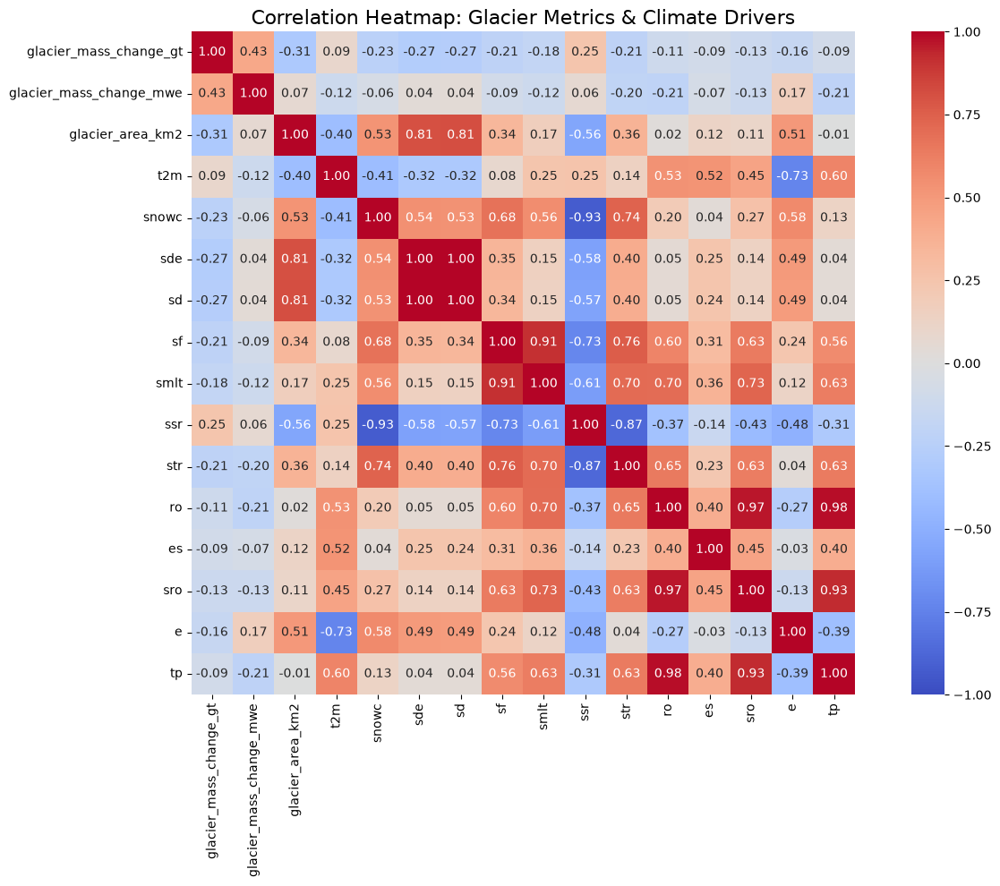

In [23]:
# Select numeric columns relevant to correlation analysis
correlation_cols = [
    'glacier_mass_change_gt', 'glacier_mass_change_mwe', 'glacier_area_km2',
    't2m', 'snowc', 'sde', 'sd', 'sf', 'smlt', 'ssr', 'str', 'ro', 'es', 'sro', 'e', 'tp'
]

# Calculate correlation matrix
corr_matrix = df[correlation_cols].corr()

# Generate heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation Heatmap: Glacier Metrics & Climate Drivers", fontsize=16)
plt.tight_layout()
plt.show()

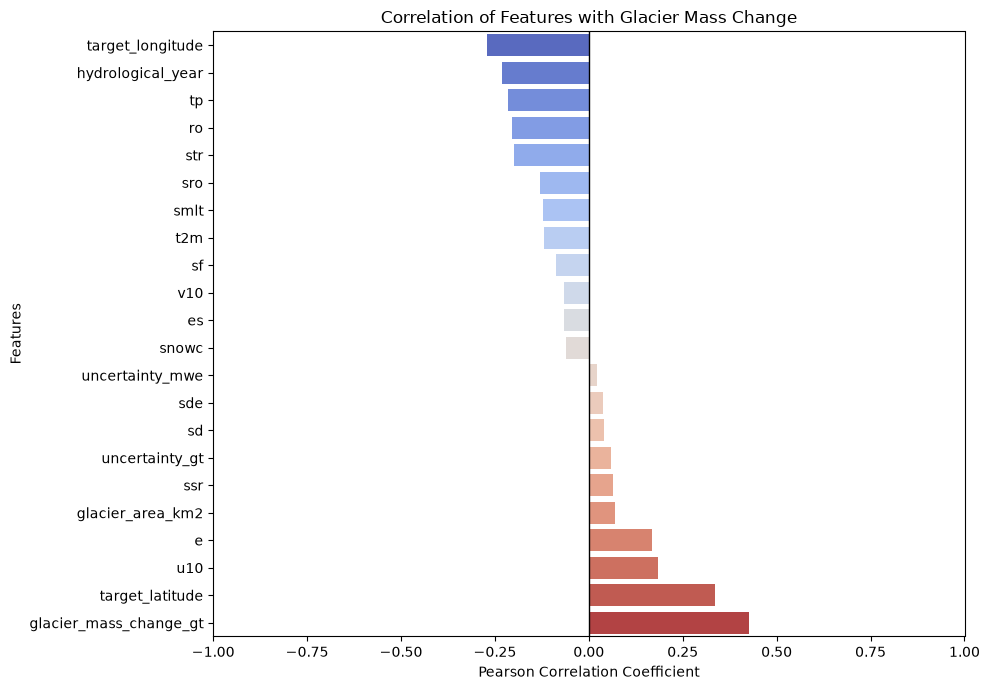

In [24]:
# Define target variable
target = 'glacier_mass_change_mwe'

# Select numerical columns
numeric_df = df.select_dtypes(include='number')

# Calculate correlation with target
correlations = numeric_df.corr()[target].drop(target)

# Sort correlations
correlations = correlations.sort_values(ascending=True)

# Plot
plt.figure(figsize=(10, 7))

sns.barplot(
    x=correlations.values,
    y=correlations.index,
    hue=correlations.index,
    palette='coolwarm',
    legend=False
)

plt.axvline(x=0, color='black', linewidth=1)

plt.title('Correlation of Features with Glacier Mass Change')
plt.xlabel('Pearson Correlation Coefficient')
plt.ylabel('Features')
plt.xlim(-1, 1)

plt.tight_layout()
plt.show()

## 5. Temporal patterns in glacier mass change

Annual summaries describe the spatial distribution of the target values across the grid in each hydrological year. The mean across grid cells is **not automatically an area-weighted HKH-wide mass balance**; it gives each included grid-cell record equal weight. The annual series is useful for exploratory comparison, but a trend should not be called “accelerating” unless an appropriate model explicitly tests changes in trend.


glacier_mass_change_gt                                \
                                   count      mean    median       std   
hydrological_year                                                        
1991                                 697 -0.054351 -0.012155  0.101745   
1992                                 697  0.020417  0.001198  0.064814   
1993                                 697  0.059792  0.011485  0.122192   
1994                                 697 -0.029622 -0.004671  0.067550   
1995                                 697 -0.039553 -0.005374  0.093063   
1996                                 697 -0.008468 -0.000714  0.050295   
1997                                 697 -0.138522 -0.029750  0.274883   
1998                                 697 -0.006535 -0.000616  0.076006   
1999                                 697 -0.017125 -0.002319  0.073825   
2000                                 697  0.021082  0.000874  0.083503   
2001                                 697 -0.032279 -0.007024  0.070373   
2002                                 697 -0.010985 -0.001486  0.069538   
2003                                 697 -0.020755 -0.000252  0.089313   
2004                                 697 -0.036418 -0.004363  0.086931   
2005                                 697  0.012342  0.000127  0.086498   
2006                                 697 -0.083060 -0.016021  0.165811   
2007                                 697 -0.052036 -0.008082  0.111868   
2008                                 697 -0.067652 -0.013323  0.139880   
2009                                 697  0.034122  0.002658  0.137104   
2010                                 697  0.006820 -0.000742  0.110206   
2011                                 697  0.014927  0.000775  0.048016   
2012                                 697 -0.046774 -0.010713  0.089152   
2013                                 697 -0.008207 -0.000399  0.047489   
2014                                 697 -0.038105 -0.007828  0.074407   
2015                                 697 -0.027431 -0.006069  0.052989   
2016                                 697  0.007964  0.000130  0.064152   
2017                                 697 -0.046538 -0.011359  0.086860   
2018                                 697 -0.032328 -0.003550  0.096210   
2019                                 697 -0.032029 -0.006456  0.076156   
2020                                 697  0.009042  0.000051  0.088569   
2021                                 697 -0.024172 -0.001130  0.089106   
2022                                 697 -0.087011 -0.022450  0.155831   
2023                                 697 -0.077622 -0.022304  0.136487   
2024                                 697 -0.087327 -0.026155  0.150129   

                                      glacier_mass_change_mwe            \
                        min       max                   count      mean   
hydrological_year                                                         
1991              -0.967941  0.042009                     697 -0.551666   
1992              -0.317064  0.581792                     697  0.127747   
1993              -0.056957  1.252720                     697  0.473917   
1994              -0.562731  0.155670                     697 -0.249549   
1995              -0.657737  0.158282                     697 -0.290303   
1996              -0.379676  0.239443                     697 -0.049882   
1997              -2.476935 -0.000017                     697 -1.094131   
1998              -0.690453  0.590689                     697 -0.194851   
1999              -0.657625  0.393107                     697 -0.275882   
2000              -0.396373  0.902138                     697  0.087402   
2001              -0.770114  0.065174                     697 -0.380963   
2002              -0.672142  0.526226                     697 -0.226575   
2003              -0.670781  0.355963                     697 -0.076961   
2004              -0.617647  0.190846                     697 -0.286489   
2005

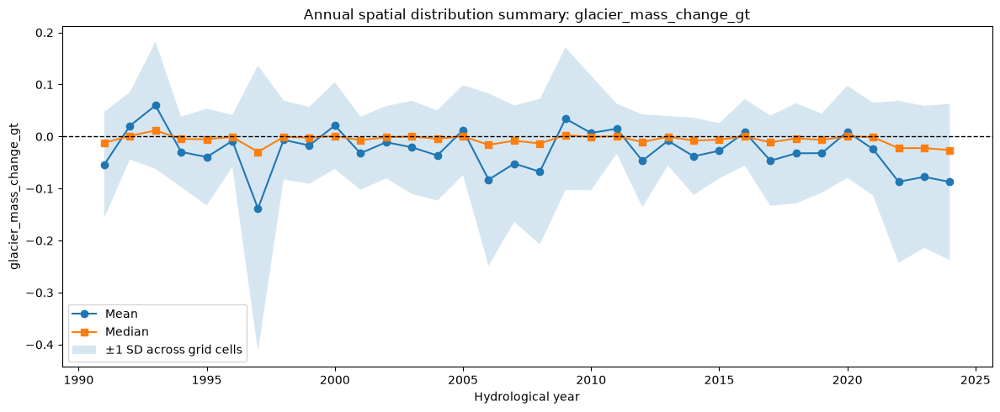

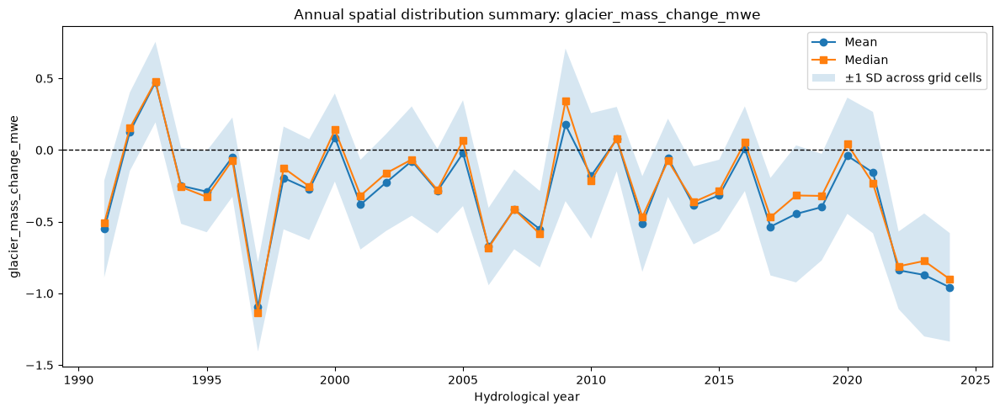

In [26]:
# Annual distribution: mean, median, spread, and sample size.
annual_target_summary = df.groupby(YEAR_COL)[TARGETS].agg(['count','mean','median','std','min','max'])
display(annual_target_summary)

for target in TARGETS:
    annual = df.groupby(YEAR_COL)[target].agg(['mean','median','std','count']).reset_index()
    fig, ax = plt.subplots(figsize=(12,5))
    ax.plot(annual[YEAR_COL],annual['mean'],marker='o',label='Mean')
    ax.plot(annual[YEAR_COL],annual['median'],marker='s',label='Median')
    ax.fill_between(annual[YEAR_COL],
                    annual['mean']-annual['std'],
                    annual['mean']+annual['std'],alpha=.18,label='±1 SD across grid cells')
    ax.axhline(0,color='black',ls='--',lw=1)
    ax.set_title(f'Annual spatial distribution summary: {target}')
    ax.set_xlabel('Hydrological year'); ax.set_ylabel(target); ax.legend()
    plt.tight_layout(); plt.show()


### 5.1 Temporal patterns in ERA5-Land climate predictors

The next cells plot annual means of the already-prepared climate columns across the grid. These plots summarize temporal variation in the supplied annual table; they do not recalculate annual climate totals. For variables that are physically accumulated (for example, precipitation or radiation), confirm the upstream aggregation and units before interpreting the plotted values as annual totals or fluxes.


In [27]:
# List of climate variables
climate_variables = [
    't2m', 'snowc', 'sd', 'sf',
    'smlt', 'ssr', 'str', 'ro', 'es',
    'sro', 'e', 'u10', 'v10', 'tp'
]

# Define annual aggregation
annual_trends = (
    df.groupby('hydrological_year')[climate_variables]
      .mean()
      .reset_index()
      .sort_values('hydrological_year')
)

# Display results
display(annual_trends.head())

,hydrological_year,t2m,snowc,sd,sf,smlt,ssr,str,ro,es,sro,e,u10,v10,tp
0,1991,268.433435,42.825988,0.374956,0.391509,0.365921,137.724736,-80.400405,0.562043,-0.033330,0.315359,-0.342350,0.508174,0.341363,0.895695
1,1992,268.105658,43.731025,0.383318,0.426246,0.358498,133.785451,-78.184621,0.564045,-0.032510,0.310934,-0.329252,0.566265,0.412376,0.942370
2,1993,268.084834,43.782958,0.375117,0.385766,0.389059,135.944164,-79.698378,0.517451,-0.036300,0.295163,-0.335945,0.551856,0.374561,0.833416
3,1994,268.452639,42.452422,0.369509,0.386114,0.338051,137.021763,-79.967075,0.511904,-0.032921,0.278902,-0.340608,0.634901,0.393273,0.872507
4,1995,268.265403,42.205900,0.371160,0.357498,0.337134,138.960089,-80.589667,0.479359,-0.033573,0.273204,-0.352463,0.537424,0.389462,0.826021


,t2m,snowc,sde,sd,sf,smlt,ssr,str,ro,es,sro,e,u10,v10,tp
hydrological_year,,,,,,,,,,,,,,,
1991,268.433435,42.825988,1.289031,0.374956,0.391509,0.365921,137.724736,-80.400405,0.562043,-0.033330,0.315359,-0.342350,0.508174,0.341363,0.895695
1992,268.105658,43.731025,1.319916,0.383318,0.426246,0.358498,133.785451,-78.184621,0.564045,-0.032510,0.310934,-0.329252,0.566265,0.412376,0.942370
1993,268.084834,43.782958,1.278516,0.375117,0.385766,0.389059,135.944164,-79.698378,0.517451,-0.036300,0.295163,-0.335945,0.551856,0.374561,0.833416
1994,268.452639,42.452422,1.275047,0.369509,0.386114,0.338051,137.021763,-79.967075,0.511904,-0.032921,0.278902,-0.340608,0.634901,0.393273,0.872507
1995,268.265403,42.205900,1.272407,0.371160,0.357498,0.337134,138.960089,-80.589667,0.479359,-0.033573,0.273204,-0.352463,0.537424,0.389462,0.826021


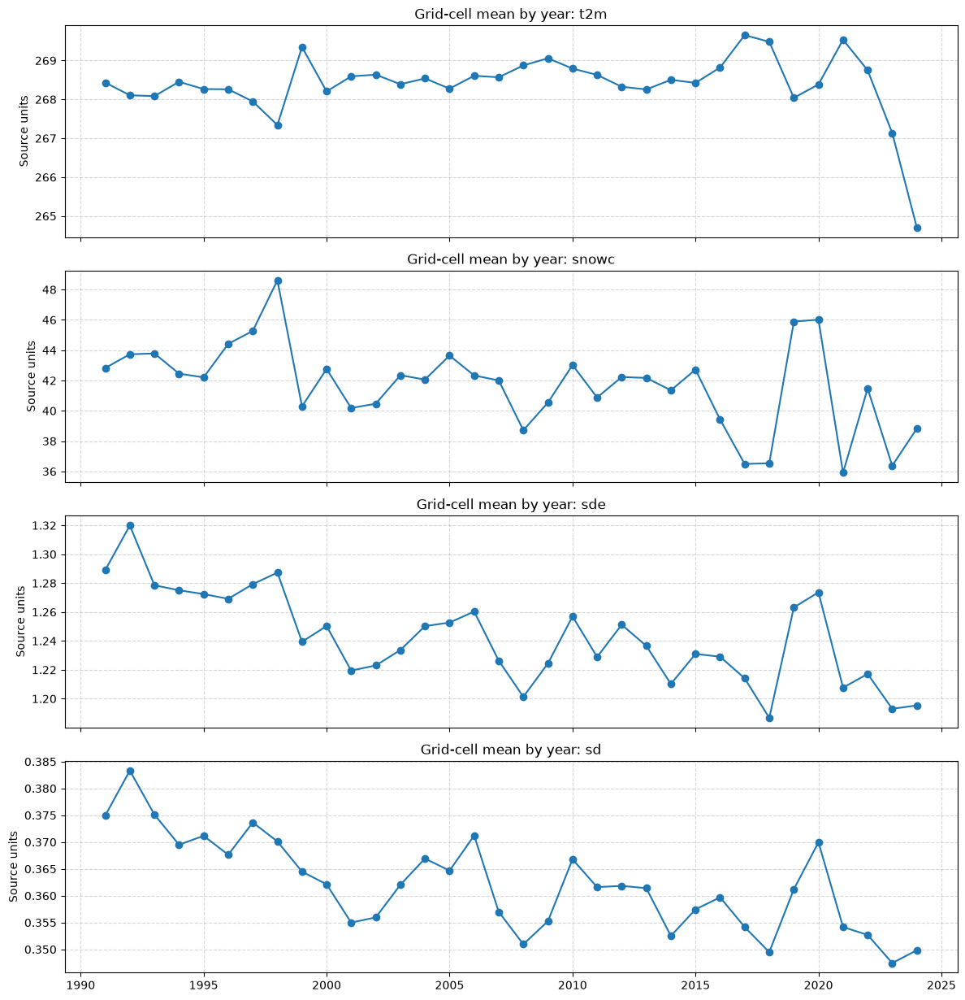

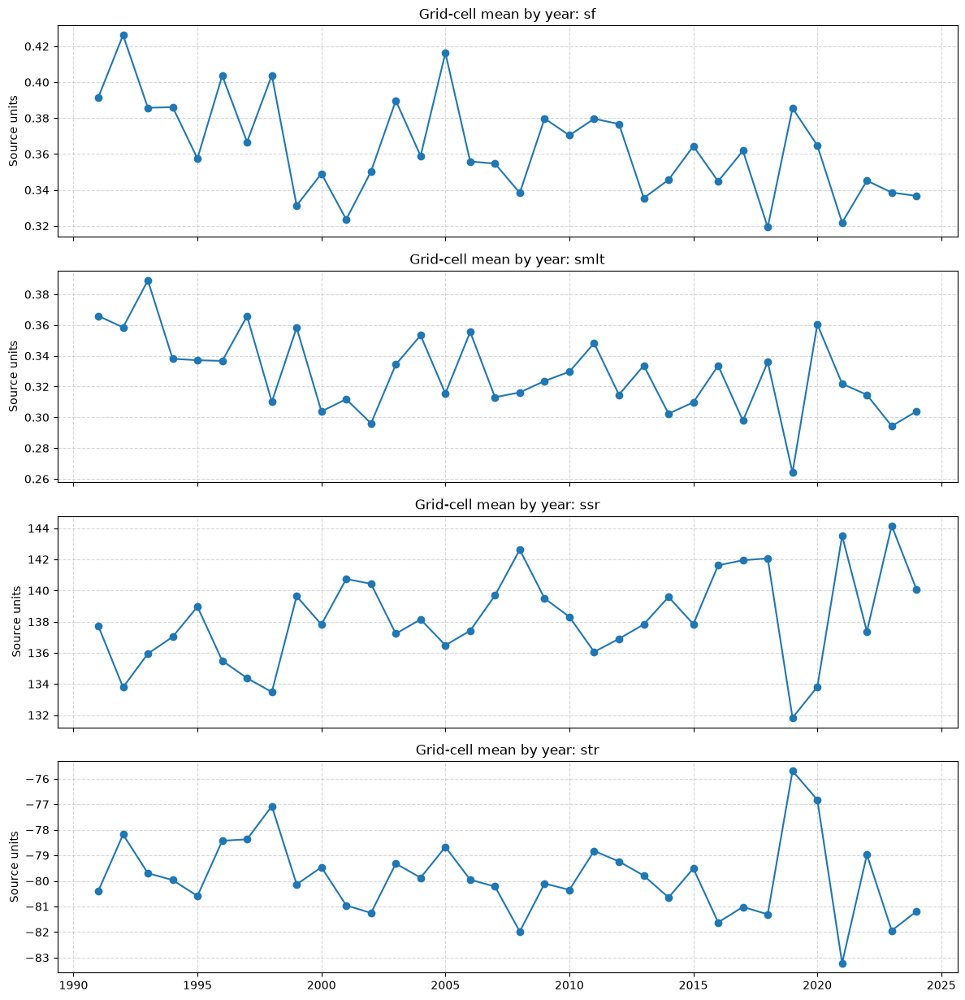

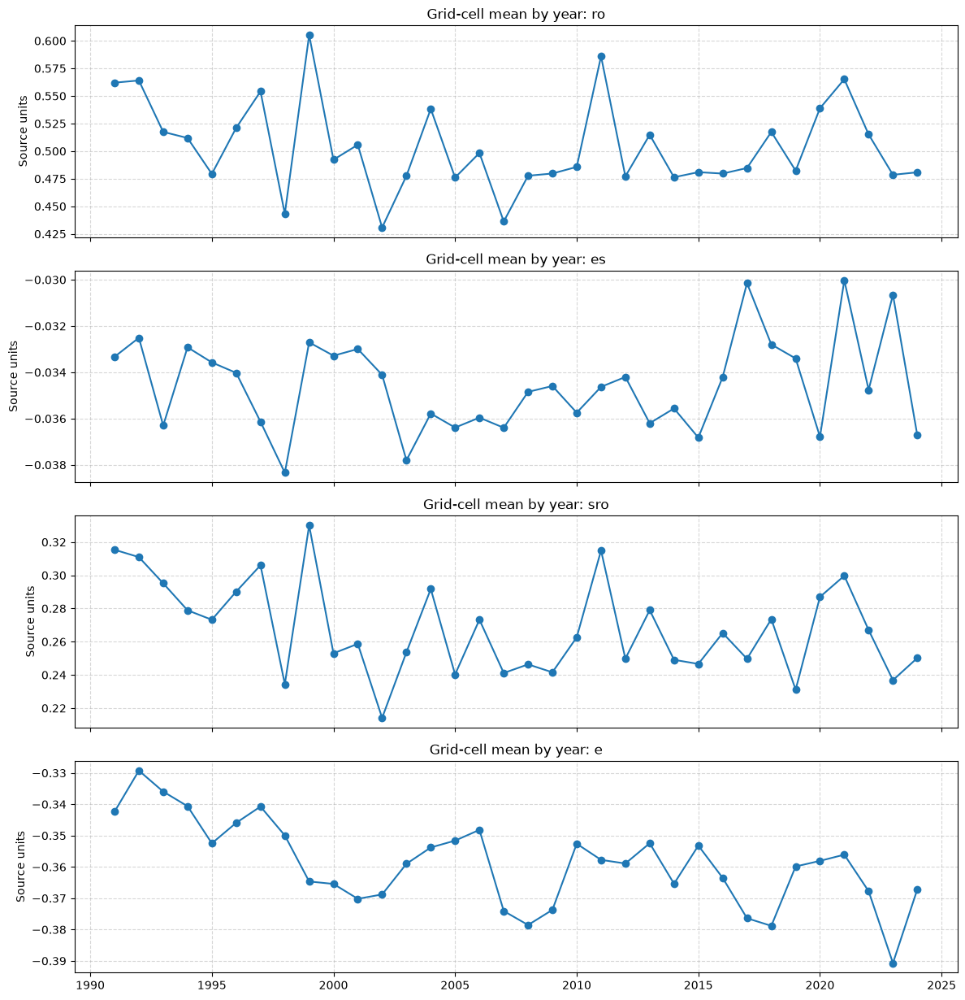

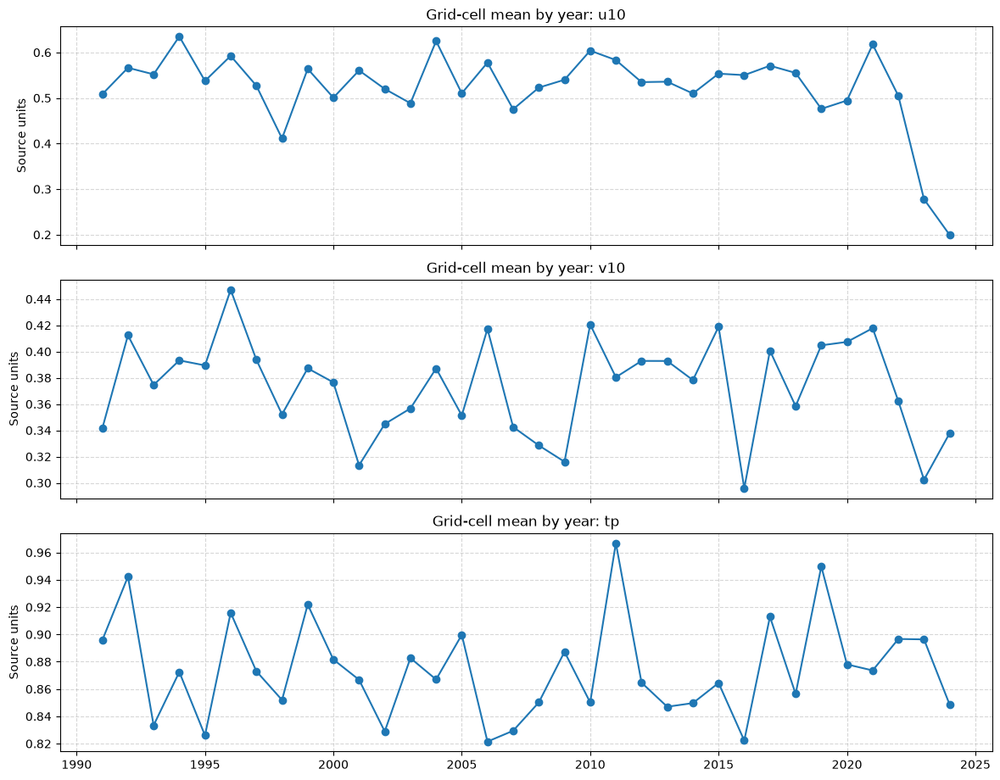

In [28]:
annual_climate = df.groupby(YEAR_COL)[CLIMATE].mean(numeric_only=True)
display(annual_climate.head())

for start in range(0,len(CLIMATE),4):
    batch=CLIMATE[start:start+4]
    fig,axes=plt.subplots(len(batch),1,figsize=(12,3.1*len(batch)),sharex=True)
    if len(batch)==1: axes=[axes]
    for ax,col in zip(axes,batch):
        ax.plot(annual_climate.index,annual_climate[col],marker='o')
        ax.set_title(f'Grid-cell mean by year: {col}')
        ax.set_ylabel('Source units')
        ax.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout(); plt.show()

## 6. Spatial patterns across the HKH grid

The following plots and interactive maps show how climate variables and the supplied specific mass-change estimates vary across target grid-cell coordinates. These are grid-level visualizations, not glacier-outline maps. Because the footprint is broader than Nepal and no stable glacier identifiers or outline overlay are used here, do not interpret an individual marker as a particular named glacier.


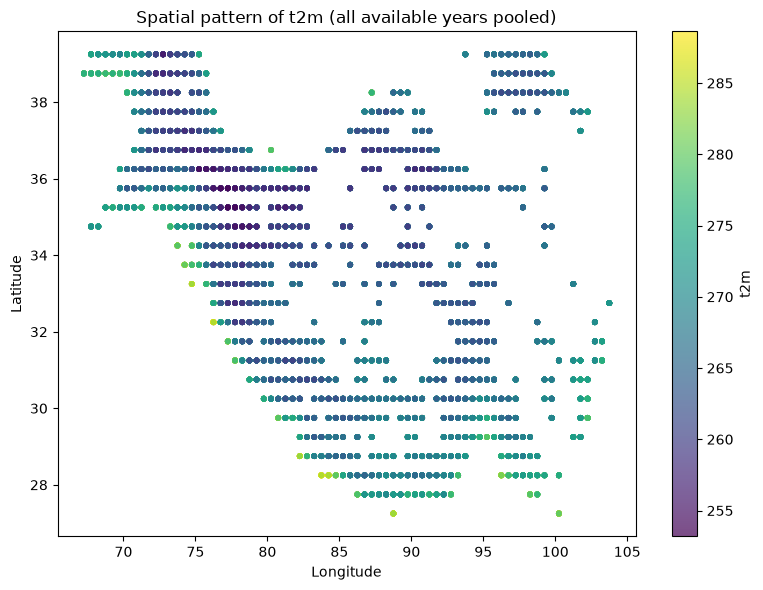

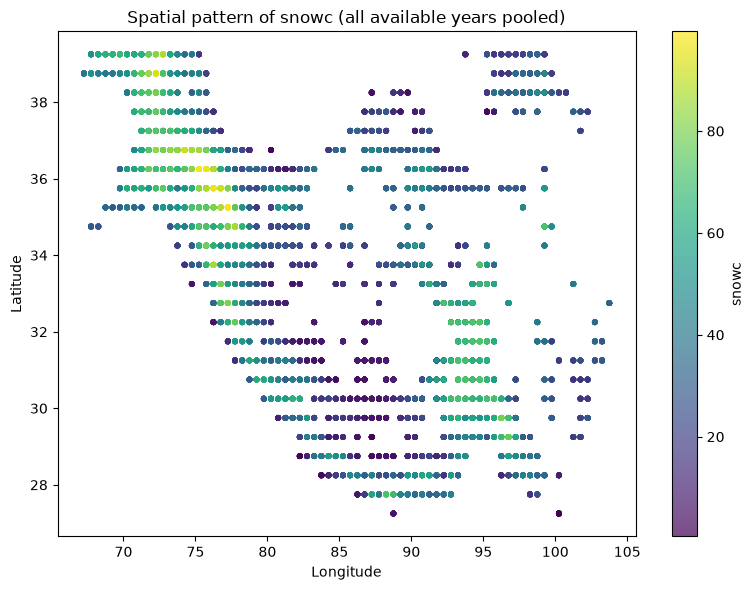

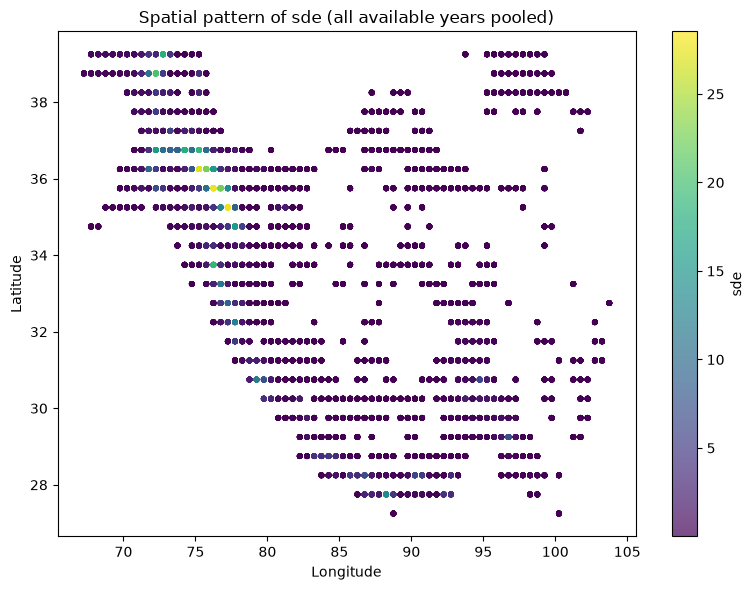

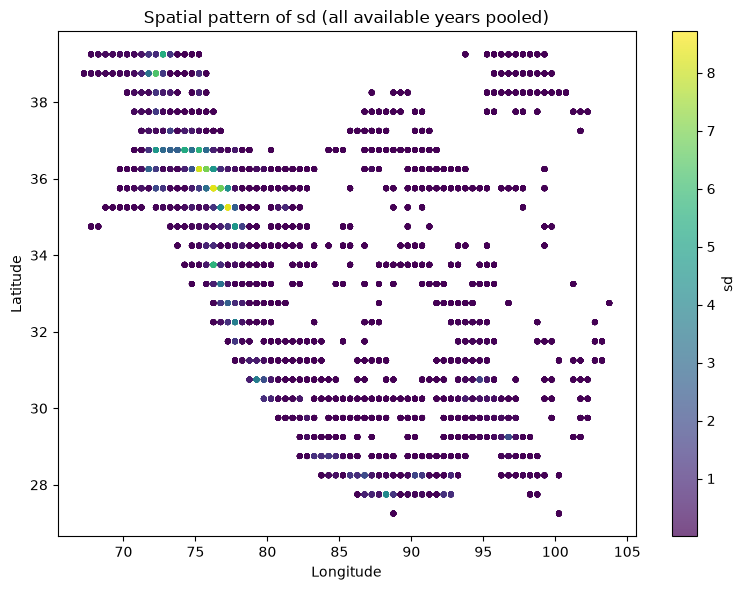

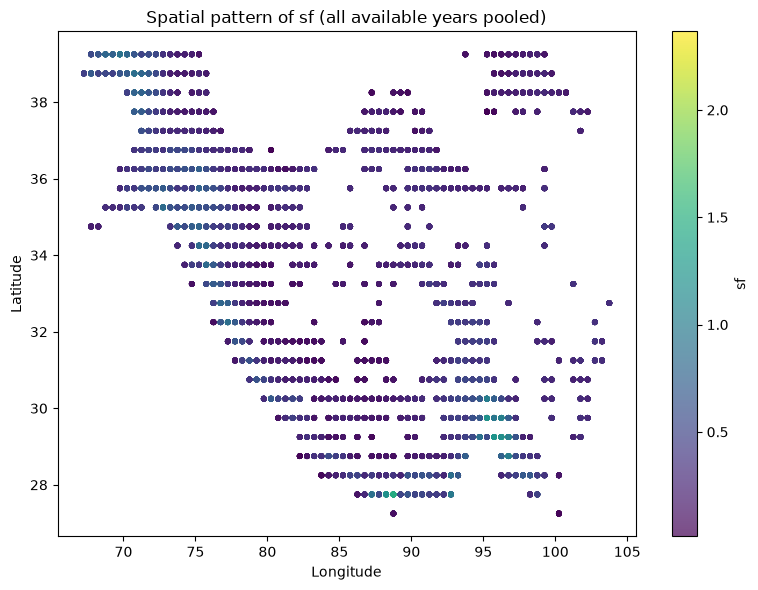

...

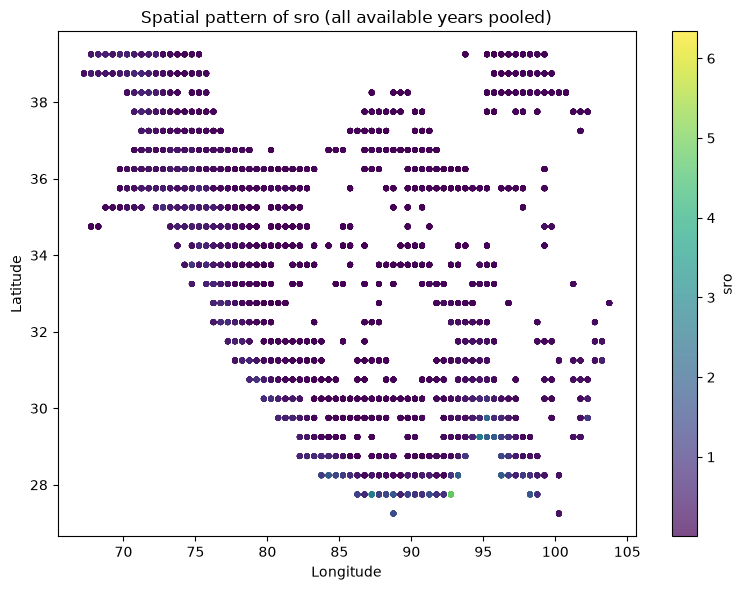

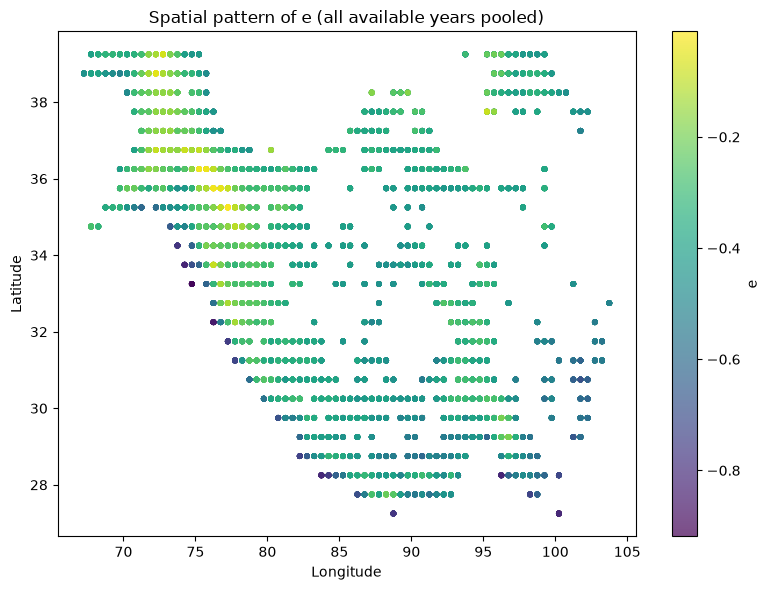

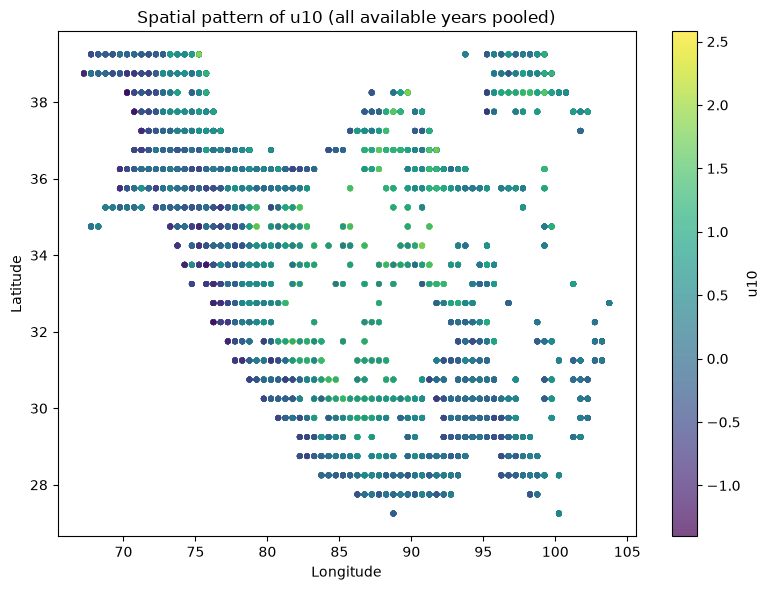

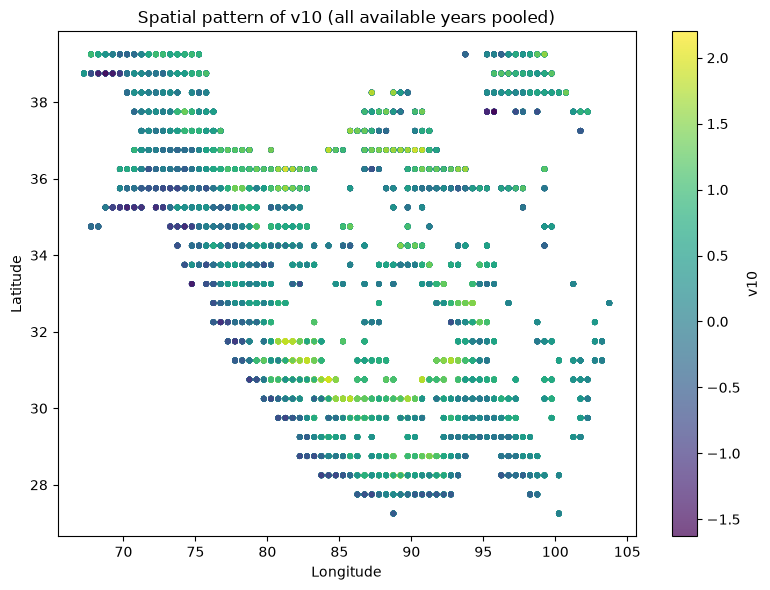

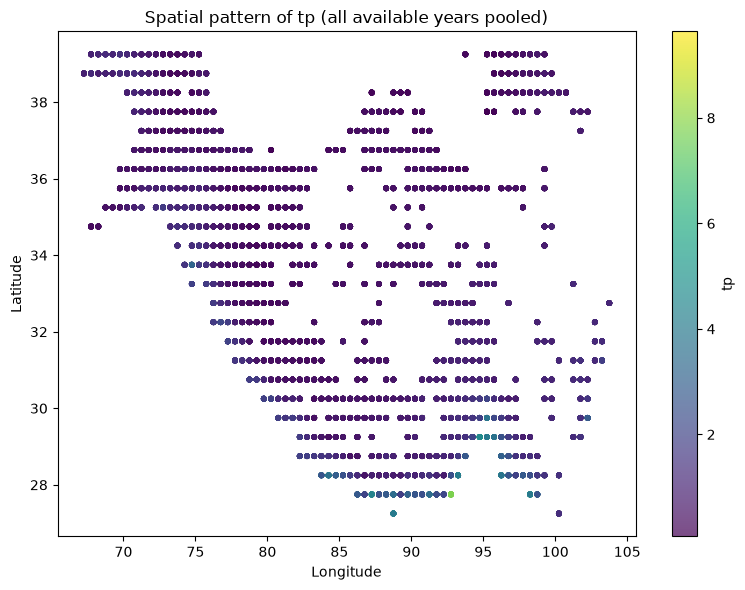

In [29]:
# Inspect climate variables against latitude and longitude to identify spatial gradients.
for col in CLIMATE:
    sample=df[[LAT_COL,LON_COL,col]].dropna()
    if len(sample)>0:
        plt.figure(figsize=(8,6))
        sc=plt.scatter(sample[LON_COL],sample[LAT_COL],c=sample[col],
                       s=10,alpha=.7,cmap='viridis')
        plt.colorbar(sc,label=col)
        plt.xlabel('Longitude'); plt.ylabel('Latitude')
        plt.title(f'Spatial pattern of {col} (all available years pooled)')
        plt.tight_layout(); plt.show()


In [30]:
import folium
import branca.colormap as cm
from folium.plugins import Fullscreen
from IPython.display import display

# ==========================================
# 1. GENERATE A MAP FOR EACH CLIMATE VARIABLE
# ==========================================

for col in CLIMATE:

    # Extract required columns and remove missing values
    sample = df[[LAT_COL, LON_COL, col]].dropna()

    if len(sample) == 0:
        continue

    # Aggregate across all available years
    spatial_data = (
        sample.groupby([LAT_COL, LON_COL])[col]
        .mean()
        .reset_index()
    )

    # Map center
    center_lat = spatial_data[LAT_COL].mean()
    center_lon = spatial_data[LON_COL].mean()

    # Variable range for color scaling
    vmin = spatial_data[col].min()
    vmax = spatial_data[col].max()

    if vmin == vmax:
        vmax = vmin + 1e-9

    # ==========================================
    # 2. CREATE BASE MAP
    # ==========================================

    m = folium.Map(
        location=[center_lat, center_lon],
        zoom_start=5,
        tiles=None,
        control_scale=True
    )

    # Esri basemap
    folium.TileLayer(
        tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}',
        attr='Esri',
        name='Esri Topographic Map'
    ).add_to(m)

    # ==========================================
    # 3. CREATE COLOR SCALE
    # ==========================================

    colormap = cm.LinearColormap(
        colors=['blue', 'cyan', 'yellow', 'red'],
        vmin=vmin,
        vmax=vmax,
        caption=f'{col} (Mean)'
    )

    # ==========================================
    # 4. PLOT SPATIAL DISTRIBUTION
    # ==========================================

    for _, row in spatial_data.iterrows():

        value = row[col]

        folium.CircleMarker(
            location=[row[LAT_COL], row[LON_COL]],
            radius=5,
            color=colormap(value),
            fill=True,
            fill_color=colormap(value),
            fill_opacity=0.8,
            weight=1,
            tooltip=f'{col}: {value:.4f}',
            popup=folium.Popup(
                f"""
                <b>Variable:</b> {col}<br>
                <b>Latitude:</b> {row[LAT_COL]:.3f}<br>
                <b>Longitude:</b> {row[LON_COL]:.3f}<br>
                <b>Mean Value:</b> {value:.4f}
                """,
                max_width=250
            )
        ).add_to(m)

    # Add color legend
    colormap.add_to(m)

    # Fullscreen control
    Fullscreen().add_to(m)

    # ==========================================
    # 5. DISPLAY MAP
    # ==========================================

    print(f"Spatial distribution of {col}")
    display(m)

Spatial distribution of t2m


Spatial distribution of snowc


Spatial distribution of sde


Spatial distribution of sd


Spatial distribution of sf


Spatial distribution of smlt


Spatial distribution of ssr


Spatial distribution of str


Spatial distribution of ro


Spatial distribution of es


Spatial distribution of sro


Spatial distribution of e


Spatial distribution of u10


Spatial distribution of v10


Spatial distribution of tp


### 6.1 Interactive map of mean specific mass change

The map displays the mean `glacier_mass_change_mwe` at each target coordinate across the available years. Negative values indicate negative mass change under the target product's sign convention; confirm that convention in the source documentation. Marker size uses mean `glacier_area_km2` as a visual cue only. A multi-year mean map does not show the trend, and the area values should not be summed or interpreted as a validated glacier inventory without checking how area was assigned to grid cells.


In [31]:
import folium
import branca.colormap as cm
from folium.plugins import Fullscreen
from IPython.display import display

# ==========================================
# 1. SPATIAL AGGREGATION
# ==========================================

spatial_mass = (
    df.groupby([LAT_COL, LON_COL])
    .agg({
        'glacier_mass_change_mwe': 'mean',
        'glacier_area_km2': 'mean'
    })
    .reset_index()
    .dropna(subset=[
        LAT_COL,
        LON_COL,
        'glacier_mass_change_mwe',
        'glacier_area_km2'
    ])
)

# ==========================================
# 2. MAP CENTER
# ==========================================

center_lat = spatial_mass[LAT_COL].mean()
center_lon = spatial_mass[LON_COL].mean()

# ==========================================
# 3. DIVERGING COLOR SCALE
# ==========================================

# Center color scale at zero
max_abs = max(
    abs(spatial_mass['glacier_mass_change_mwe'].min()),
    abs(spatial_mass['glacier_mass_change_mwe'].max())
)

if max_abs == 0:
    max_abs = 1e-9

colormap = cm.LinearColormap(
    colors=['red', 'yellow', 'blue'],
    vmin=-max_abs,
    vmax=max_abs,
    caption='Mean Glacier Mass Change (m w.e.)'
)

# ==========================================
# 4. CREATE BASE MAP
# ==========================================

m_mass = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=5,
    tiles=None,
    control_scale=True
)

# Esri World Topographic Map
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles © Esri and its contributors',
    name='Esri Topographic Map',
    overlay=False,
    control=True
).add_to(m_mass)

# ==========================================
# 5. PLOT GLACIER MASS CHANGE
# ==========================================

for _, row in spatial_mass.iterrows():

    value = row['glacier_mass_change_mwe']
    area = row['glacier_area_km2']

    # Marker color based on mass change
    color = colormap(value)

    # Marker radius based on glacier area
    radius = max(3, min(15, area * 0.1))

    # Classify mass change
    if value < 0:
        status = 'Mass Loss'
    elif value > 0:
        status = 'Mass Gain'
    else:
        status = 'No Net Change'

    folium.CircleMarker(
        location=[
            row[LAT_COL],
            row[LON_COL]
        ],

        radius=radius,

        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.8,
        weight=1,

        tooltip=f'{status}: {value:.3f} m w.e.',

        popup=folium.Popup(
            f"""
            <b>Glacier Information</b><br><br>

            <b>Latitude:</b> {row[LAT_COL]:.3f}<br>
            <b>Longitude:</b> {row[LON_COL]:.3f}<br>

            <hr>

            <b>Mean Mass Change:</b> {value:.3f} m w.e.<br>
            <b>Mean Glacier Area:</b> {area:.2f} km²<br>

            <b>Status:</b> {status}
            """,
            max_width=300
        )

    ).add_to(m_mass)

# ==========================================
# 6. ADD LEGEND AND CONTROLS
# ==========================================

colormap.add_to(m_mass)

Fullscreen().add_to(m_mass)

folium.LayerControl().add_to(m_mass)

# ==========================================
# 7. DISPLAY MAP
# ==========================================

display(m_mass)

### 6.2 Scatter map of grid-cell specific mass change

Each point represents a target grid coordinate, with color indicating the supplied specific mass-change value and marker size scaled by `glacier_area_km2`. This plot can reveal broad spatial heterogeneity, but it does not account for spatial autocorrelation, topography, glacier boundaries, or differences in uncertainty. Treat it as exploratory visualization rather than a glacier-level attribution analysis.


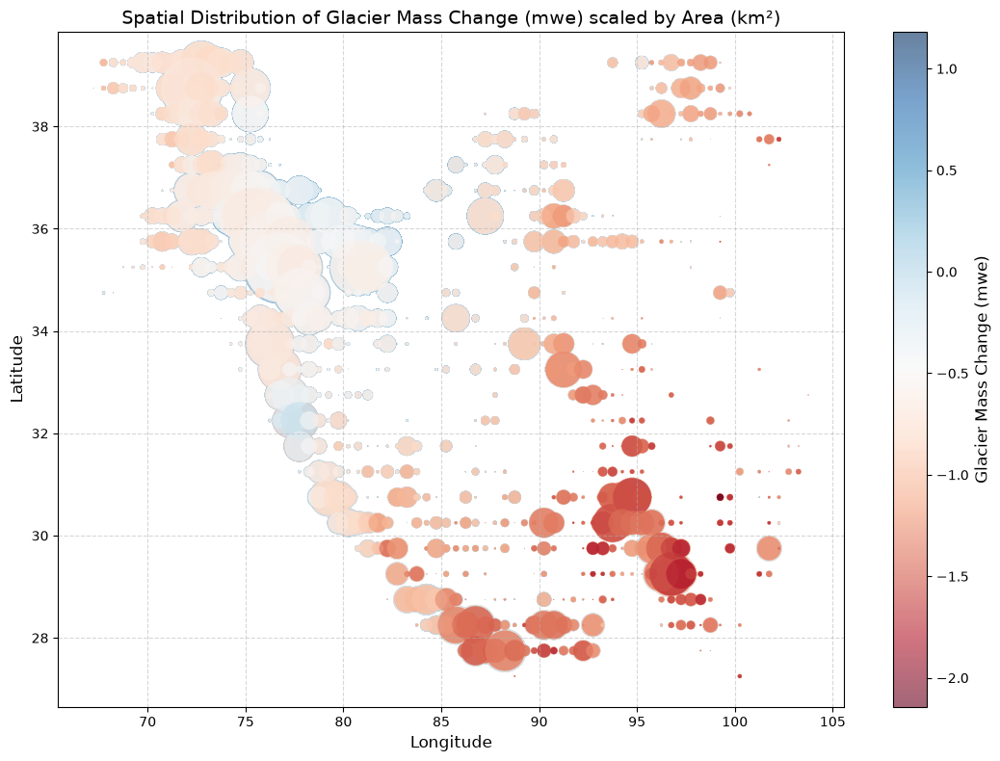

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 8))
sc = plt.scatter(
    df['target_longitude'],
    df['target_latitude'],
    c=df['glacier_mass_change_mwe'],
    cmap='RdBu',
    s=df['glacier_area_km2'] * 1.5,
    alpha=0.6,
    edgecolors='none'
)
cbar = plt.colorbar(sc)
cbar.set_label('Glacier Mass Change (mwe)', fontsize=12)

plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.title('Spatial Distribution of Glacier Mass Change (mwe) scaled by Area (km²)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 7. Main Insights & Observations Summary

The findings below are based on the supplied table and the exploratory calculations in this notebook:

### 1. Dataset size, time span, and grid structure

- The table contains **23,698 rows**, covering **34 hydrological years (1991–2024)** and **697 unique target coordinate pairs**.
- Each hydrological year has **697 rows**, and each coordinate pair appears in all **34 years**. No duplicate `(hydrological_year, target_latitude, target_longitude)` keys or exact duplicate rows were detected in the audited table. This is a balanced grid-cell/year panel.
- The target coordinates span **27.25°–39.25° N** and **67.25°–103.75° E**, with a nominal **0.5° coordinate spacing**. This is a broad HKH footprint, not a Nepal-only dataset. Nepal-specific conclusions require an explicit, documented Nepal mask/subset.
- The balance of the table supports consistent longitudinal comparisons, but does **not** imply 697 independent glaciers, equal reliability across cells, or suitability for random-row train/test splitting.

### 2. Missingness and data integrity

- The principal target, area, uncertainty, and climate columns shown in the audit have no missing values in this prepared table. The year/grid-cell key is unique and panel coverage is complete.
- These checks establish internal completeness only. They do not confirm that all source data are physically correct, that the monthly-to-hydrological-year aggregation is correct, or that the target estimates are unbiased.
- The input file contains period and monthly-coverage audit fields, but the loading step drops several of those auxiliary fields from the analysis frame. Retain the original CSV and review those fields or the upstream processing audit when verifying temporal completeness.

### 3. Overall distribution of the mass-change target

- Across all **23,698 grid-cell/year records**, `glacier_mass_change_mwe` has a mean of approximately **−0.297 m w.e.**, a median of **−0.278 m w.e.**, and a standard deviation of approximately **0.478 m w.e.** The observed range is **−2.143 to +1.181 m w.e.** in the supplied values.
- Approximately **72.27%** of the `glacier_mass_change_mwe` records are negative, **27.66%** are positive, and **0.08%** are exactly zero. The corresponding negative proportion for `glacier_mass_change_gt` is approximately **72.30%**.
- These percentages are record-level proportions, not the percentage of glaciers losing mass and not an area-weighted proportion of total HKH glacier mass. They also do not establish that every glacier or every region experienced loss.

### 4. Temporal variation: negative overall tendency, but not a monotonic or proven accelerating decline

- The equal-grid-cell annual mean of `glacier_mass_change_mwe` varies substantially from year to year. In the supplied series, the most positive annual mean is approximately **+0.474 m w.e. in 1993**, while the most negative is approximately **−1.094 m w.e. in 1997**. The 2022–2024 annual means are also strongly negative; the 2024 mean is approximately **−0.958 m w.e.**
- A simple ordinary least-squares line fitted to the 34 annual grid-cell means has a slope of about **−0.0113 m w.e. per year of calendar trend** (`r ≈ −0.327`, nominal `p ≈ 0.059`). This is a descriptive, unadjusted trend; under conventional assumptions it does not cross the 0.05 significance threshold, and those assumptions are questionable because the annual means arise from spatially dependent grid cells and may be temporally autocorrelated.
- Therefore, the EDA is consistent with an overall negative tendency in this prepared series, but it does **not** establish statistically robust acceleration. The annual sequence is variable and includes positive-mean years.

### 5. Climate relationships: modest pooled correlations, not causal effects

- In the pooled table, the Pearson correlation between `tp` and `glacier_mass_change_mwe` is approximately **−0.215**; for `t2m` and `glacier_mass_change_mwe`, it is approximately **−0.119**. These are weak-to-modest negative linear associations, not the exceptionally strong positive precipitation relationship claimed in the earlier summary.
- The sign and magnitude of these pooled correlations may be influenced by spatial gradients, temporal patterns, correlated predictors, and the construction of the target product. A negative pooled precipitation correlation does not mean precipitation causes mass loss; precipitation phase, elevation, seasonality, and snowfall versus rainfall matter.
- Temperature and precipitation relationships should be re-examined using within-grid-cell anomalies, lagged/seasonal features where justified, and spatially/temporally blocked validation. Unit and aggregation checks are required before physical interpretation of climate variables.

### 6. Uncertainty matters

- The target table includes `uncertainty_gt` and `uncertainty_mwe`, but the uncertainty fields are not small relative to every estimate. For `uncertainty_mwe`, the median uncertainty is approximately **0.186 m w.e.**, while the median absolute target value is approximately **0.278 m w.e.**; the median uncertainty-to-absolute-estimate ratio is approximately **0.505** among nonzero estimates.
- Ratios become extremely large when the estimated change is near zero, so the ratio's mean and maximum are unstable and should not be used as standalone quality scores. Check the source definition and confidence level of the uncertainty fields, and propagate uncertainty into downstream conclusions where possible.

### 7. Spatial heterogeneity and scope of inference

- The maps show substantial variation among grid cells. Such variation may reflect climate, elevation, glacier characteristics, target-product uncertainty, and spatial aggregation; the current EDA cannot isolate those explanations.
- Coordinates and grid-cell averages alone do not identify individual glaciers. Glacier-specific claims require an authoritative glacier inventory, outlines, and a documented grid-to-glacier overlay or another validated glacier-level dataset.
- Since the current footprint extends well beyond Nepal, results should be labelled **HKH-wide** unless the analysis is filtered to a well-defined Nepal boundary and that subset is re-audited.

### 8. Implications for future predictive modelling

- The table is suitable for further **exploratory modelling design**, but the EDA alone does not establish predictive performance.
- Define the prediction target and forecast horizon first. If predicting a future hydrological year, use only predictors available at the forecast origin; same-year climate aggregates may be retrospective and can cause information leakage if used to claim a forecast made before that year ends.
- Do not randomly split rows from the same grid cells and years into train/test sets. Use forward-chaining or blocked temporal validation and, if the intended use is geographic transfer, a spatial holdout as well. Compare against simple baselines, inspect residual spatial/temporal structure, and report uncertainty.
- Before modelling, verify original variable metadata and aggregation, review the known ERA5-Land monthly accumulated-field issue affecting September 2022–February 2024 if those source months contribute to the prepared dataset, and document any exclusions or corrections. Do not infer that issue has been resolved merely because the annual table has no missing values.

### Overall conclusion

The prepared dataset is internally complete and balanced at the grid-cell/year level, and its pooled specific mass-change values are predominantly negative. However, annual values vary considerably, simple trend evidence is not conclusive, and pooled climate correlations are modest and non-causal. The strongest next steps are to verify source units and temporal aggregation, clarify uncertainty and target-product provenance, separate Nepal from the broader HKH footprint if Nepal is the research focus, and design leakage-safe temporal/spatial validation before claiming predictive capability.
